In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('BankChurners.csv')

# 1 = churned, 0 = still a customer (easier to average than text)
df['churned'] = (df['Attrition_Flag'] == 'Attrited Customer').astype(int)

print('Rows, columns:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Churn rate:', round(df['churned'].mean() * 100, 2), '%')
df.head()

Rows, columns: (10127, 22)
Missing values: 0
Churn rate: 16.07 %


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,churned
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0


In [ ]:
df.groupby('Attrition_Flag')[['Total_Trans_Ct', 'Total_Trans_Amt']].median()

,Total_Trans_Ct,Total_Trans_Amt
Attrition_Flag,,
Attrited Customer,43.0,2329.0
Existing Customer,71.0,4100.0


In [ ]:
df.groupby('Attrition_Flag')[['Total_Trans_Ct', 'Total_Trans_Amt']].agg(['mean', 'median']).round(2)

Total_Trans_Ct        Total_Trans_Amt        
                            mean median            mean  median
Attrition_Flag                                                 
Attrited Customer          44.93   43.0         3095.03  2329.0
Existing Customer          68.67   71.0         4654.66  4100.0

util_band
Zero               36.15
Low (0-25%)        10.11
Medium (25-50%)     9.52
High (50-100%)      8.94
Name: churned, dtype: float64


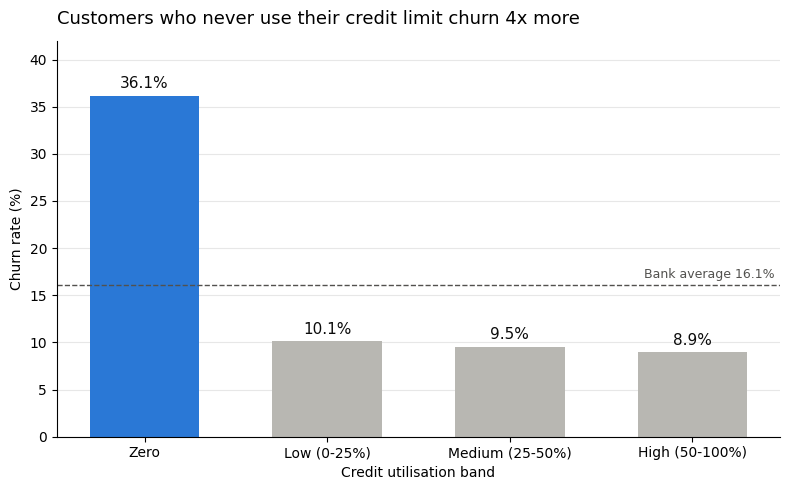

In [ ]:
import numpy as np

# Same bands as your SQL CASE WHEN (checked top to bottom, first match wins)
conditions = [
    df['Avg_Utilization_Ratio'] == 0,
    df['Avg_Utilization_Ratio'] < 0.25,
    df['Avg_Utilization_Ratio'] < 0.50,
]
choices = ['Zero', 'Low (0-25%)', 'Medium (25-50%)']
df['util_band'] = np.select(conditions, choices, default='High (50-100%)')

# Churn rate per band = GROUP BY util_band, AVG(churned) * 100
order = ['Zero', 'Low (0-25%)', 'Medium (25-50%)', 'High (50-100%)']
util = df.groupby('util_band')['churned'].mean().mul(100).round(2).reindex(order)
print(util)

# ---- Chart ----
overall = df['churned'].mean() * 100
colors = ['#2a78d6' if band == 'Zero' else '#b8b7b2' for band in order]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(order, util.values, color=colors, width=0.6)

# Value label on top of each bar
for bar, value in zip(bars, util.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.8, f'{value:.1f}%',
            ha='center', fontsize=11, color='#0b0b0b')

# Bank-wide average as a reference line
ax.axhline(overall, color='#52514e', linestyle='--', linewidth=1)
ax.text(3.45, overall + 0.8, f'Bank average {overall:.1f}%', ha='right',
        fontsize=9, color='#52514e')

ax.set_title('Customers who never use their credit limit churn 4x more',
             fontsize=13, loc='left', pad=12)
ax.set_xlabel('Credit utilisation band')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 42)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('chart_utilisation.png', dpi=150)
plt.show()

Months_Inactive_12_mon
1     4.48
2    15.39
3    21.48
4    29.89
5    17.98
6    15.32
Name: churned, dtype: float64


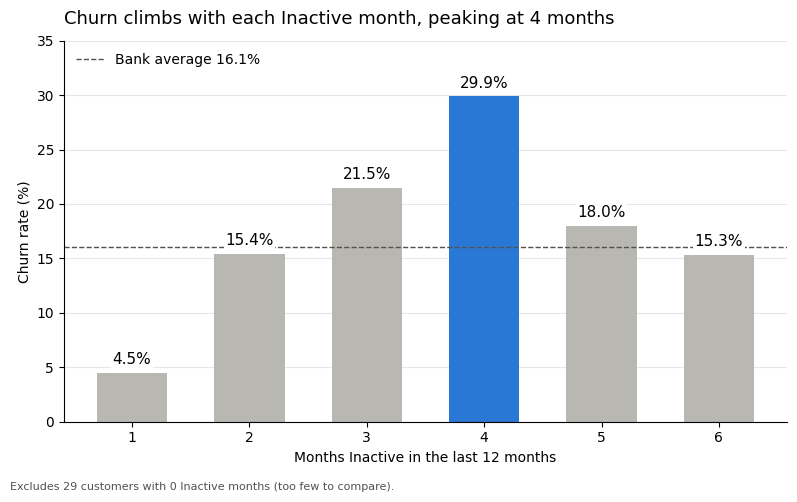

In [ ]:
# Churn rate by months Inactive (leave out the 29 customers with 0 months)
Inactive = (df[df['Months_Inactive_12_mon'] > 0]
            .groupby('Months_Inactive_12_mon')['churned'].mean().mul(100).round(2))
print(Inactive)

# Highlight the 4-month bar
colors = ['#2a78d6' if m == 4 else '#b8b7b2' for m in Inactive.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(Inactive.index.astype(str), Inactive.values, color=colors, width=0.6)

for bar, value in zip(bars, Inactive.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.8, f'{value:.1f}%', ha='center', fontsize=11,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

ax.axhline(overall, color='#52514e', linestyle='--', linewidth=1, label=f'Bank average {overall:.1f}%')
ax.legend(frameon=False, loc='upper left')

ax.set_title('Churn climbs with each Inactive month, peaking at 4 months', fontsize=13, loc='left', pad=12)   # write a title that states the finding
ax.set_xlabel('Months Inactive in the last 12 months')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 35)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

fig.text(0.01, 0.01, 'Excludes 29 customers with 0 Inactive months (too few to compare).',
         fontsize=8, color='#52514e')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig('chart_inactive.png', dpi=150)
plt.show()

Contacts_Count_12_mon
0      1.75
1      7.20
2     12.49
3     20.15
4     22.63
5     33.52
6    100.00
Name: churned, dtype: float64


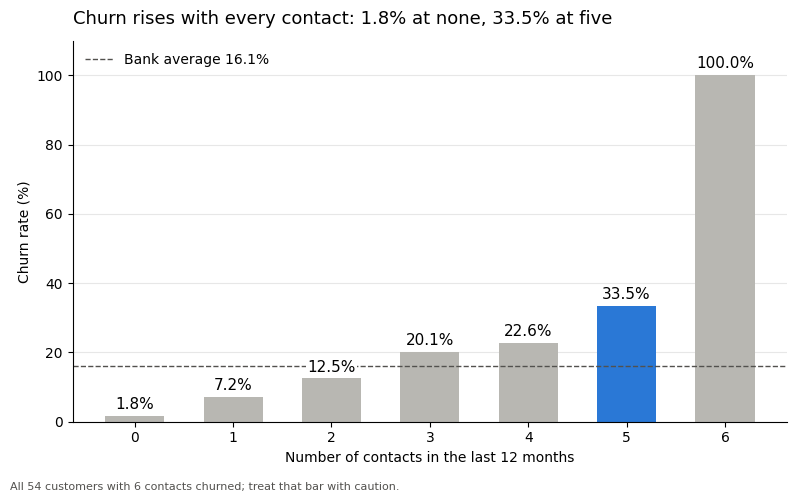

In [ ]:
# Churn rate by number of contacts
contacts = (df.groupby('Contacts_Count_12_mon')['churned'].mean().mul(100).round(2))
print(contacts)

# Highlight the 5-month bar
colors = ['#2a78d6' if m == 5 else '#b8b7b2' for m in contacts.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(contacts.index.astype(str), contacts.values, color=colors, width=0.6)

for bar, value in zip(bars, contacts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 2, f'{value:.1f}%', ha='center', fontsize=11,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

ax.axhline(overall, color='#52514e', linestyle='--', linewidth=1, label=f'Bank average {overall:.1f}%')
ax.legend(frameon=False, loc='upper left')

ax.set_title('Churn rises with every contact: 1.8% at none, 33.5% at five', fontsize=13, loc='left', pad=12)   # write a title that states the finding
ax.set_xlabel('Number of contacts in the last 12 months')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 110)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

fig.text(0.01, 0.01, 'All 54 customers with 6 contacts churned; treat that bar with caution.',
         fontsize=8, color='#52514e')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig('chart_contacts.png', dpi=150)
plt.show()

Total_Relationship_Count
1    25.60
2    27.84
3    17.35
4    11.77
5    12.00
6    10.50
Name: churned, dtype: float64


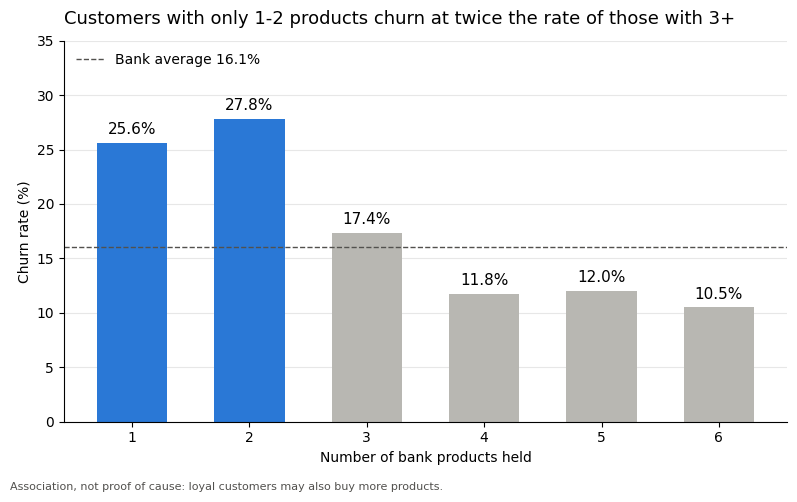

In [ ]:
# Churn rate by number of Relationships
Relationships = (df.groupby('Total_Relationship_Count')['churned'].mean().mul(100).round(2))
print(Relationships)

# Highlight the 1&2-month bar
colors = ['#2a78d6' if m in [1,2] else '#b8b7b2' for m in Relationships.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(Relationships.index.astype(str), Relationships.values, color=colors, width=0.6)

for bar, value in zip(bars, Relationships.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.8, f'{value:.1f}%', ha='center', fontsize=11,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

ax.axhline(overall, color='#52514e', linestyle='--', linewidth=1, label=f'Bank average {overall:.1f}%')
ax.legend(frameon=False, loc='upper left')

ax.set_title('Customers with only 1-2 products churn at twice the rate of those with 3+', fontsize=13, loc='left', pad=12)   # write a title that states the finding
ax.set_xlabel('Number of bank products held')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 35)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

fig.text(0.01, 0.01, 'Association, not proof of cause: loyal customers may also buy more products.',
         fontsize=8, color='#52514e')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig('chart_products.png', dpi=150)
plt.show()

activity_change
Halved or worse      50.88
Moderate drop        12.20
Slight drop           7.64
Stable or growing     7.07
Name: churned, dtype: float64


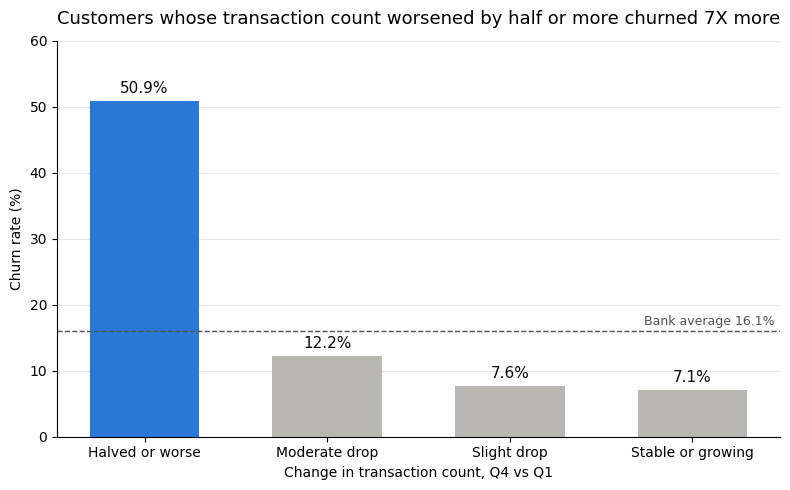

In [ ]:
# Same bands as SQL query 3.6
conditions = [
    df['Total_Ct_Chng_Q4_Q1'] < 0.5,
    df['Total_Ct_Chng_Q4_Q1'] < 0.8,
    df['Total_Ct_Chng_Q4_Q1'] < 1.0,
]
choices = ['Halved or worse', 'Moderate drop', 'Slight drop']
df['activity_change'] = np.select(conditions, choices, default='Stable or growing')

order = ['Halved or worse', 'Moderate drop', 'Slight drop', 'Stable or growing']
change = df.groupby('activity_change')['churned'].mean().mul(100).round(2).reindex(order)
print(change)

# ---- Chart ----
overall = df['churned'].mean() * 100
colors = ['#2a78d6' if band == 'Halved or worse' else '#b8b7b2' for band in order]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(order, change.values, color=colors, width=0.6)

# Value label on top of each bar
for bar, value in zip(bars, change.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.2, f'{value:.1f}%',
            ha='center', fontsize=11, color='#0b0b0b')

# Bank-wide average as a reference line
ax.axhline(overall, color='#52514e', linestyle='--', linewidth=1)
ax.text(3.45, overall + 0.8, f'Bank average {overall:.1f}%', ha='right',
        fontsize=9, color='#52514e')

ax.set_title('Customers whose transaction count worsened by half or more churned 7X more',
             fontsize=13, loc='left', pad=12)
ax.set_xlabel('Change in transaction count, Q4 vs Q1')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 60)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('chart_transaction_changes.png', dpi=150)
plt.show()

In [ ]:
# One flag per warning sign: 1 = red flag, 0 = fine.
# Thresholds come from the SQL and chart findings.
df['flag_zero_util']       = (df['Avg_Utilization_Ratio'] == 0).astype(int)
df['flag_activity_halved'] = (df['Total_Ct_Chng_Q4_Q1'] < 0.5).astype(int)
df['flag_inactive_3plus']  = (df['Months_Inactive_12_mon'] >= 3).astype(int)
df['flag_contacts_3plus']  = (df['Contacts_Count_12_mon'] >= 3).astype(int)
df['flag_few_products']    = (df['Total_Relationship_Count'] <= 2).astype(int)

flags = ['flag_zero_util', 'flag_activity_halved', 'flag_inactive_3plus',
         'flag_contacts_3plus', 'flag_few_products']

# Risk score = number of red flags (0 to 5)
df['risk_score'] = df[flags].sum(axis=1)

# Does churn rise with the score?
risk = df.groupby('risk_score').agg(customers=('churned', 'size'),
                                    churned=('churned', 'sum'),
                                    churn_rate=('churned', 'mean'))
risk['churn_rate'] = (risk['churn_rate'] * 100).round(2)
risk['share_of_all_churners'] = (risk['churned'] / df['churned'].sum() * 100).round(1)
risk


,customers,churned,churn_rate,share_of_all_churners
risk_score,,,,
0,1543,28,1.81,1.7
1,3746,214,5.71,13.2
2,3132,464,14.81,28.5
3,1306,591,45.25,36.3
4,350,280,80.00,17.2
5,50,50,100.00,3.1


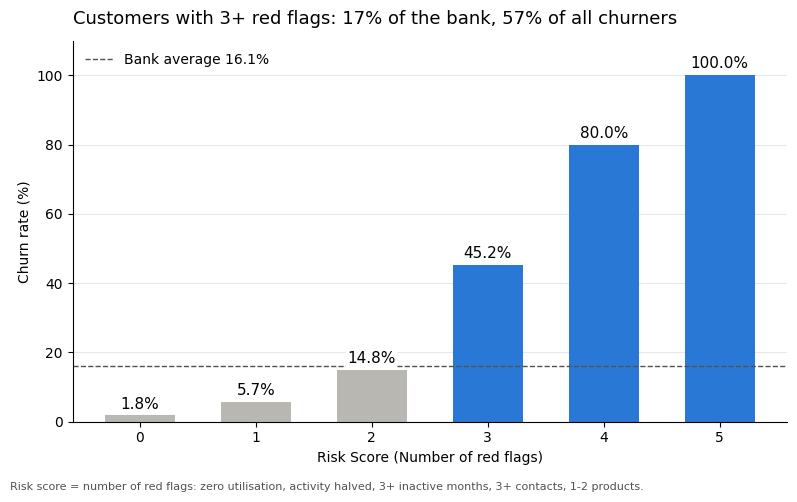

In [ ]:
risks = risk['churn_rate']
# Highlight the watch-list: 3+ flags
colors = ['#2a78d6' if m in [3,4,5] else '#b8b7b2' for m in risks.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(risks.index.astype(str), risks.values, color=colors, width=0.6)

for bar, value in zip(bars, risks.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 2.0, f'{value:.1f}%', ha='center', fontsize=11,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

ax.axhline(overall, color='#52514e', linestyle='--', linewidth=1, label=f'Bank average {overall:.1f}%')
ax.legend(frameon=False, loc='upper left')

ax.set_title('Customers with 3+ red flags: 17% of the bank, 57% of all churners', fontsize=13, loc='left', pad=12)   # write a title that states the finding
ax.set_xlabel('Risk Score (Number of red flags)')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 110)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

fig.text(0.01, 0.01, 'Risk score = number of red flags: zero utilisation, activity halved, '
         '3+ inactive months, 3+ contacts, 1-2 products.', fontsize=8, color='#52514e')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig('chart_risks.png', dpi=150)
plt.show()

In [ ]:
# Prefixed labels ("1. ", "2. ") so Power BI sorts the bands in the right order
df['age_band'] = np.select(
    [df['Customer_Age'] < 35, df['Customer_Age'] < 45, df['Customer_Age'] < 55],
    ['1. Under 35', '2. 35-44', '3. 45-54'], default='4. 55+')
df['util_band'] = np.select(
    [df['Avg_Utilization_Ratio'] == 0, df['Avg_Utilization_Ratio'] < 0.25, df['Avg_Utilization_Ratio'] < 0.5],
    ['1. Zero', '2. Low (0-25%)', '3. Medium (25-50%)'], default='4. High (50-100%)')
df['activity_change'] = np.select(
    [df['Total_Ct_Chng_Q4_Q1'] < 0.5, df['Total_Ct_Chng_Q4_Q1'] < 0.8, df['Total_Ct_Chng_Q4_Q1'] < 1.0],
    ['1. Halved or worse', '2. Moderate drop', '3. Slight drop'], default='4. Stable or growing')
df['risk_group'] = np.where(df['risk_score'] >= 3, 'Watch-list (3+ flags)', 'Lower risk (0-2 flags)')

df.to_csv('bankchurners_powerbi.csv', index=False)
print(df.shape)   # expect (10127, 32)

(10127, 32)
